## Deep Learning

### Exercice 1: Perceptron simple

#### Etape 1: Importer les librairies

In [57]:
import numpy as np
import pandas as pd

#### Etape 2: Définir les données d'entraînement

In [58]:
X = np.array([[0,1], [0,1], [1,0], [1,1]])
y = np.array([0, 0, 0, 1])

In [59]:
df_X = pd.DataFrame(X, columns=['Feature1', 'Feature2'])
print("DataFrame X:")
print(df_X)

DataFrame X:
   Feature1  Feature2
0         0         1
1         0         1
2         1         0
3         1         1


In [60]:
#Création d'un DataFrame pour y (optionnel)
df_y = pd.DataFrame(y, columns=['Target'])
print("DataFrame y:")
print(df_y)

DataFrame y:
   Target
0       0
1       0
2       0
3       1


### Etape 3: Initialiser les poids et le bias

In [61]:
np.random.seed(42)  # Pour la reproductibilité
w = np.random.rand(2)  # Poids aléatoires pour les deux caractéristiques
b = np.random.rand(1)  # Biais aléatoire
print("Initial weights:", w)
print("Initial bias:", b)

Initial weights: [0.37454012 0.95071431]
Initial bias: [0.73199394]


#### Etape 4: Définir la fonction d'activation (Sigmoïde)

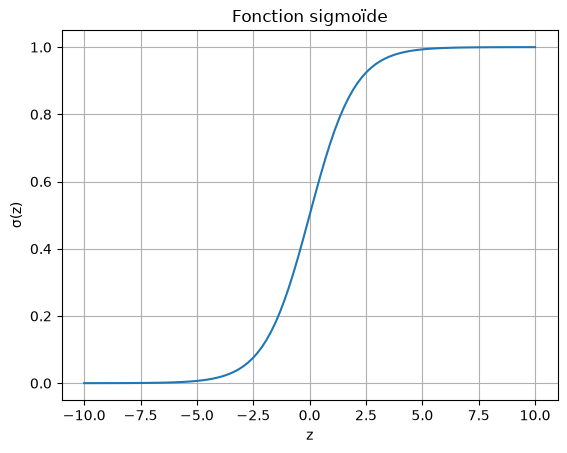

In [62]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))
sigmoid(1)  # Test de la fonction sigmoïde

#plot the sigmoid function
import matplotlib.pyplot as plt
x = np.linspace(-10, 10, 100)
y = sigmoid(x)
plt.plot(x, y)
plt.xlabel('z')
plt.ylabel('σ(z)')
plt.title('Fonction sigmoïde')
plt.grid(True)
plt.show()

#### Etape 5: Définir la prédiction du perceptron

In [63]:
def predict(X, w, b):
    z = np.dot(X, w) + b
    return sigmoid(z)

#### Etape 6: Définir la fonction de perte (MSE)

In [64]:
def loss(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)  # Erreur quadratique moyenne

#### Etape 7: Entrainement du perceptron (descente de gradient)

In [65]:
learning_rate = 0.1
epochs = 2000
y_true = y
for i in range (epochs):
    y_pred = predict(X, w, b)
    # Calcul du gradient
    y_true = np.array([0, 0, 0, 1])  # labels de training, pas le tableau sigmoid (100,)
    y_pred = predict(X, w, b)
    dw = -2 * np.dot(X.T, (y_true - y_pred) * y_pred * (1 - y_pred)) / len(X)
    db = -2 * np.mean((y_true - y_pred) * y_pred * (1 - y_pred))
    db = -2*np.mean((y_true - y_pred)*y_pred*(1-y_pred))
    # Mise à jour des paramètres
    w = w - learning_rate * dw
    b = b - learning_rate * db
    if i % 100 == 0:
        print(f"Epoch {i}, Loss: {loss(y_true, y_pred)}")

Epoch 0, Loss: 0.49993800268980065
Epoch 100, Loss: 0.19016484993036678
Epoch 200, Loss: 0.1637686147698202
Epoch 300, Loss: 0.14610505276485863
Epoch 400, Loss: 0.13091294742744086
Epoch 500, Loss: 0.11773805992264705
Epoch 600, Loss: 0.10628661764701154
Epoch 700, Loss: 0.09632188172284979
Epoch 800, Loss: 0.08764030760329257
Epoch 900, Loss: 0.0800628250194562
Epoch 1000, Loss: 0.07343236618026125
Epoch 1100, Loss: 0.0676126556530413
Epoch 1200, Loss: 0.062486718957728546
Epoch 1300, Loss: 0.05795495845548357
Epoch 1400, Loss: 0.05393301285511523
Epoch 1500, Loss: 0.05034962318492632
Epoch 1600, Loss: 0.04714464920480363
Epoch 1700, Loss: 0.044267306134222084
Epoch 1800, Loss: 0.04167464156335378
Epoch 1900, Loss: 0.039330243928896814


#### Etape 8: Tester le perceptron

In [66]:
y_pred = predict(X, w, b)
print("Final predictions:", y_pred)
print("Classes prédites (seuil de 0.5):", (y_pred > 0.5).astype(int))

Final predictions: [0.14047434 0.14047434 0.21043646 0.74492539]
Classes prédites (seuil de 0.5): [0 0 0 1]


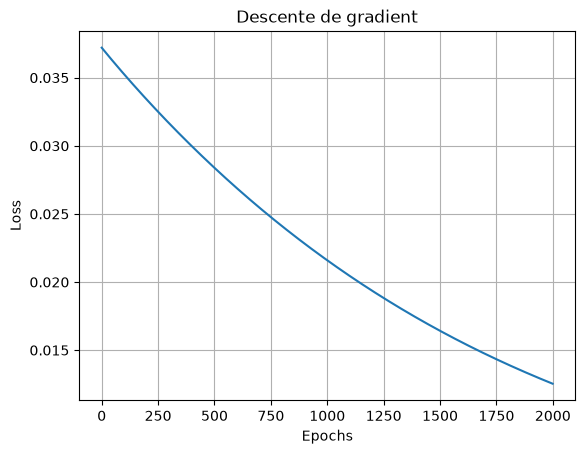

In [67]:
# plot le loss au fil des epochs
losses = []
y_true = np.array([0, 0, 0, 1])
for i in range(epochs):
    y_pred = predict(X, w, b)
    losses.append(loss(y_true, y_pred))
    # Calcul du gradient
    dw = -2 * np.dot(X.T, (y_true - y_pred) * y_pred * (1 - y_pred)) / len(X)
    # Mise à jour des paramètres
    w = w - learning_rate * dw
    b = b - learning_rate * db
plt.plot(range(epochs), losses)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Descente de gradient')
plt.grid(True)
plt.show()

#### L'entropie croisée

In [72]:
# (^y_true - y)

from operator import le


np.random.seed(42)  # Pour la reproductibilité
w = np.random.rand(2)  # Poids aléatoires pour les deux caractéristiques
b = np.random.rand(1)  # Biais aléatoire

def bce(y_true, y_pred, eps=1e-12):
    return -np.mean(y_true * np.log(y_pred + eps) + (1 - y_true) * np.log(1 - y_pred + eps))
y_true = np.array([0, 0, 0, 1])  # shape (4,), matches X
learning_rate = 0.5
for i in range(epochs):
    y_pred = predict(X, w, b)
    dz = y_pred - y_true
    w -= learning_rate * np.dot(X.T, dz) / len(X)
    b -= learning_rate * np.mean(dz)
    if i % 400 == 0:
        print(f"Epoch {i}, BCE Loss: {bce(y_true, y_pred):.4f}")
print("Final predictions:", predict(X, w, b))

Epoch 0, BCE Loss: 1.3047
Epoch 400, BCE Loss: 0.0919
Epoch 800, BCE Loss: 0.0459
Epoch 1200, BCE Loss: 0.0303
Epoch 1600, BCE Loss: 0.0225
Final predictions: [0.01038619 0.01038619 0.02082734 0.97086835]
